# Step 1 **데이터 이해**

In [1]:
# Colab setup
%pip install -q mne mne-bids openneuro-py pandas matplotlib mne-icalabel mne-connectivity

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.4/178.4 kB 13.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 48.8/48.8 MB 19.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 167.2/167.2 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.1/10.1 MB 134.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.1/86.1 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.3/207.3 kB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 74.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.2.1 which is incompatible.


In [2]:
from pathlib import Path
import mne
import numpy as np
import pandas as pd
from IPython.display import display
from mne_bids import BIDSPath, print_dir_tree, read_raw_bids
import matplotlib.pyplot as plt
from mne.preprocessing import ICA
from mne_icalabel import label_components
from mne_connectivity import spectral_connectivity_epochs, spectral_connectivity_time
from mne_connectivity.viz import plot_sensors_connectivity

In [3]:
# 필요 데이터셋 다운로드

dataset = "ds007526"
target_dir = "/content/openneuro"

subjects = ["sub-003", "sub-004"]

# 공통 메타파일 먼저 다운로드 (한 번만)
!openneuro-py download \
    --dataset={dataset} \
    --target-dir={target_dir} \
    --include=dataset_description.json \
    --include=participants.tsv \
    --include=participants.json \
    --include=README

# 각 subject 다운로드
for sub in subjects:
    print(f"Downloading {sub} ...")
    !openneuro-py download \
        --dataset={dataset} \
        --target-dir={target_dir} \
        --include={sub}/


👋 Hello! This is openneuro-py 2026.4.0. Great to see you! 🤗

   👉 Please report problems 🤯 and bugs 🪲 at
      https://github.com/openneuro-py/openneuro-py/issues

🌍 Preparing to download ds007526 …
📁 Traversing directories for ds007526 : 6 entities [00:00, 1406.86 entities/s]
📥 Retrieving up to 5 files (5 concurrent downloads). 
✅ Finished downloading ds007526.
 
🧠 Please enjoy your brains.
 

👋 Hello! This is openneuro-py 2026.4.0. Great to see you! 🤗

   👉 Please report problems 🤯 and bugs 🪲 at
      https://github.com/openneuro-py/openneuro-py/issues

🌍 Preparing to download ds007526 …
📁 Traversing directories for ds007526 : 19 entities [00:00, 87.64 entities/s]
📥 Retrieving up to 17 files (5 concurrent downloads). 
Skipping participants.tsv: already downloaded.
Skipping participants.json: already downloaded.
Skipping CHANGES: already downloaded.
Skipping dataset_description.json: already downloaded.
sub-003_task-rest_eeg.set:   0% 0.00/15.2M [00:00<?, ?B/s]
sub-003_space-CapTrak_

In [4]:
# 피험자 정보 확인

df_selected = (
    pd.read_csv(f"{target_dir}/participants.tsv", sep="\t")
    .query("participant_id in @subjects")
    .reset_index(drop=True)
)

df_selected

,participant_id,subject_id,group,updrs_part_iii,updrs_total,moca,age,sex,disease_duration,ledd,pigd_score,td_score,ctt
0,sub-003,HC0004,HC,0.0,1.0,27.0,60.0,F,NaN,NaN,NaN,NaN,63.0
1,sub-004,HC0005,HC,1.0,1.0,25.0,72.0,M,NaN,NaN,NaN,NaN,116.0


In [5]:
bids_root = "/content/openneuro"

bids_path = BIDSPath(
    root = bids_root,
    subject = "003",
    task="rest",
    datatype="eeg",
)

raw = read_raw_bids(bids_path = bids_path, verbose=True)
raw.load_data()

print(raw)

Reading /content/openneuro/sub-003/eeg/sub-003_task-rest_eeg.set
Reading events from /content/openneuro/sub-003/eeg/sub-003_task-rest_events.tsv.
Reading channel info from /content/openneuro/sub-003/eeg/sub-003_task-rest_channels.tsv.
Reading electrode coords from /content/openneuro/sub-003/eeg/sub-003_space-CapTrak_electrodes.tsv.
Reading 0 ... 60911  =      0.000 ...   243.644 secs...


/tmp/ipykernel_5043/2491409526.py:10: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = read_raw_bids(bids_path = bids_path, verbose=True)
/tmp/ipykernel_5043/2491409526.py:10: RuntimeWarning: There are channels without locations (n/a) that are not marked as bad: ['VREF']
  raw = read_raw_bids(bids_path = bids_path, verbose=True)
/tmp/ipykernel_5043/2491409526.py:10: RuntimeWarning: Unable to map the following column(s) to to MNE:
subject_id: HC0004
group: HC
updrs_part_iii: 0.0
updrs_total: 1.0
moca: 27.0
disease_duration: n/a
ledd: n/a
pigd_score: n/a
td_score: n/a
ctt: 63.0
  raw = read_raw_bids(bids_path = bids_path, verbose=True)


<RawEEGLAB | sub-003_task-rest_eeg.set, 65 x 60912 (243.6 s), ~30.3 MiB, data loaded>


Using matplotlib as 2D backend.


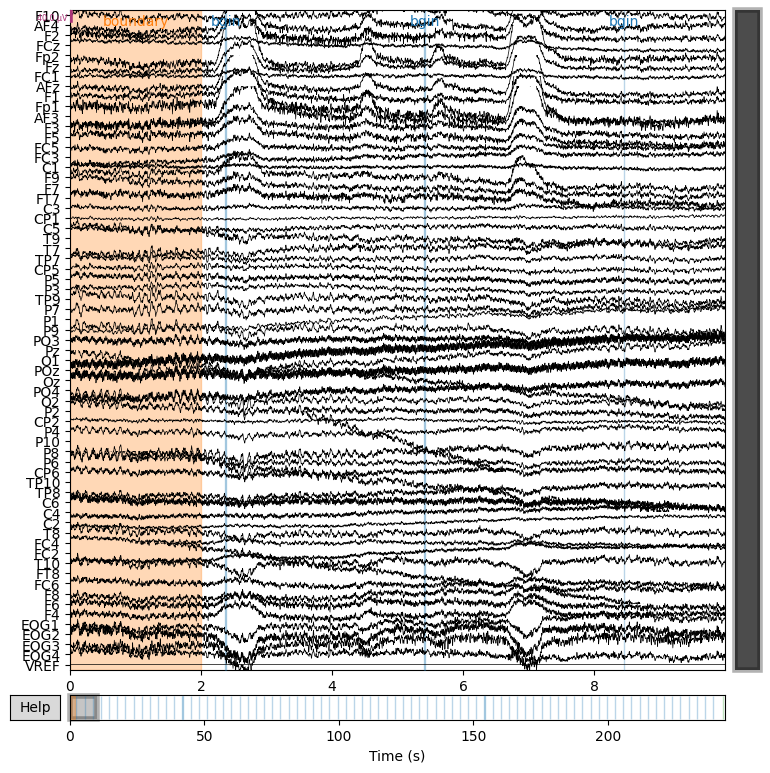

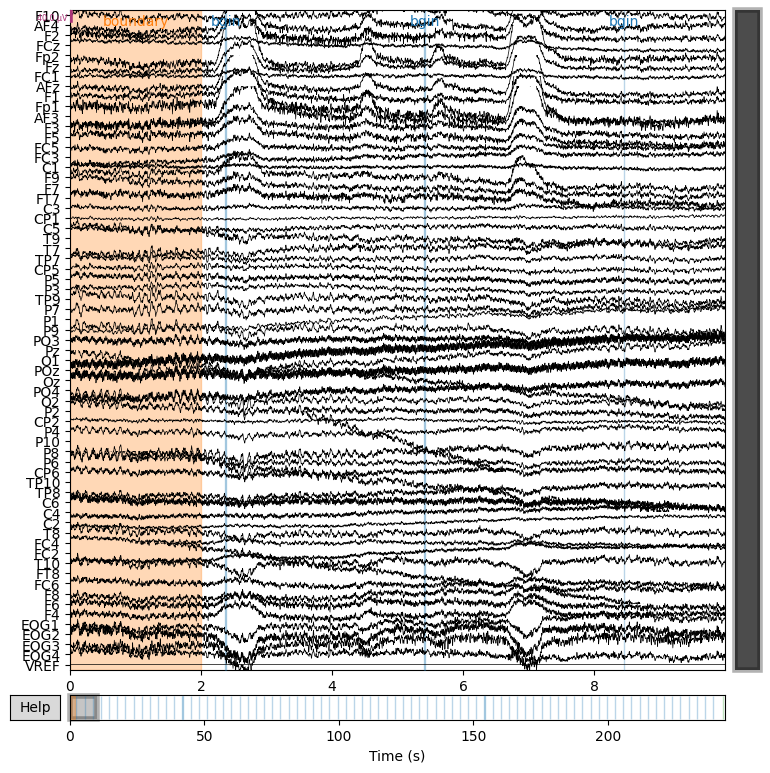

In [6]:
# raw plot

raw.plot(
    n_channels = 68,
    remove_dc = True
)

In [7]:
# 채널 이름: 종류

for name, ch_type in zip(raw.ch_names, raw.get_channel_types()):
    print(f"{name}: {ch_type}")

F10: eeg
AF4: eeg
F2: eeg
FCz: eeg
Fp2: eeg
Fz: eeg
FC1: eeg
AFz: eeg
F1: eeg
Fp1: eeg
AF3: eeg
F3: eeg
F5: eeg
FC5: eeg
FC3: eeg
C1: eeg
F9: eeg
F7: eeg
FT7: eeg
C3: eeg
CP1: eeg
C5: eeg
T9: eeg
T7: eeg
TP7: eeg
CP5: eeg
P5: eeg
P3: eeg
TP9: eeg
P7: eeg
P1: eeg
P9: eeg
PO3: eeg
Pz: eeg
O1: eeg
POz: eeg
Oz: eeg
PO4: eeg
O2: eeg
P2: eeg
CP2: eeg
P4: eeg
P10: eeg
P8: eeg
P6: eeg
CP6: eeg
TP10: eeg
TP8: eeg
C6: eeg
C4: eeg
C2: eeg
T8: eeg
FC4: eeg
FC2: eeg
T10: eeg
FT8: eeg
FC6: eeg
F8: eeg
F6: eeg
F4: eeg
EOG1: eeg
EOG2: eeg
EOG3: eeg
EOG4: eeg
VREF: eeg


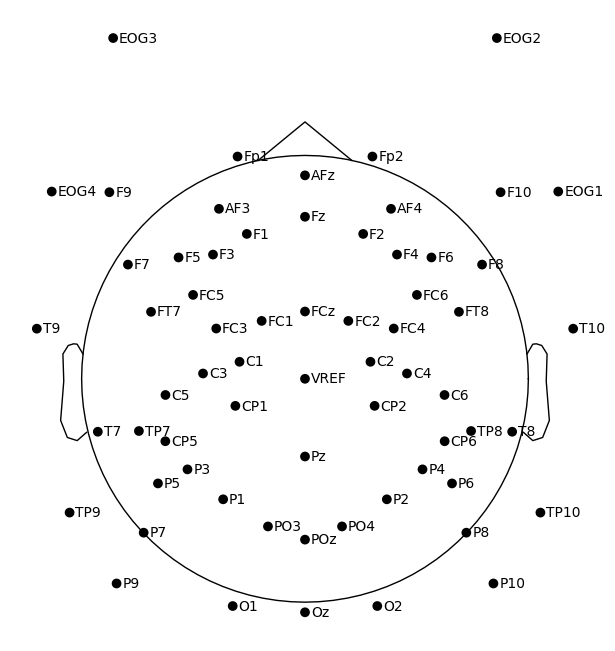

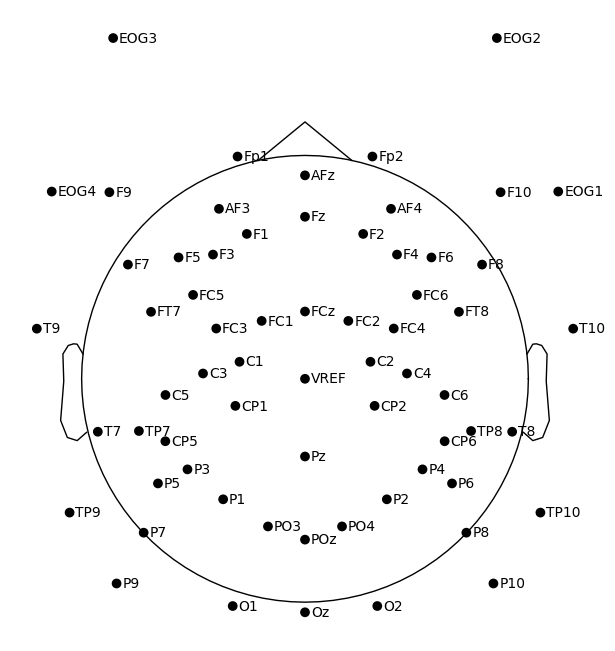

In [8]:
# 전극 위치 확인

raw.plot_sensors(show_names = True)

/tmp/ipykernel_5043/2101969291.py:5: RuntimeWarning: The unit for channel(s) VREF has changed from V to NA.
  change_channel.set_channel_types({


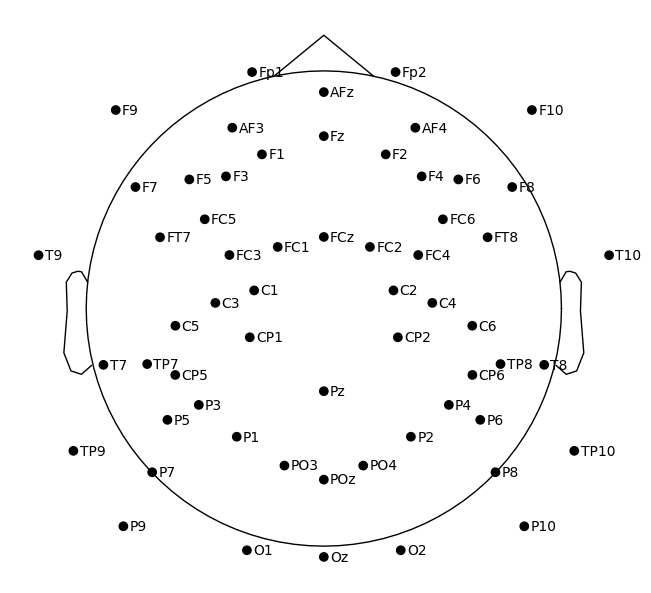

EEG: 60
EOG: 4


In [9]:
# EOG 채널, VREF 채널 변경

change_channel = raw.copy()

change_channel.set_channel_types({
    "EOG1": "eog",
    "EOG2": "eog",
    "EOG3": "eog",
    "EOG4": "eog",
    "VREF": "misc",
})

change_channel.plot_sensors(show_names=True)

print("EEG:", len(change_channel.copy().pick("eeg").ch_names))
print("EOG:", len(change_channel.copy().pick("eog").ch_names))

# Step 2 **기본 전처리**

In [10]:
crop = change_channel.copy()

crop.crop(tmin = 20,
          tmax = 200,
          include_tmax = True)

crop

<RawEEGLAB | sub-003_task-rest_eeg.set, 65 x 45001 (180.0 s), ~22.4 MiB, data loaded>

In [11]:
vref_drop = crop.copy()
vref_drop.drop_channels(["VREF"])

vref_drop

<RawEEGLAB | sub-003_task-rest_eeg.set, 64 x 45001 (180.0 s), ~22.0 MiB, data loaded>

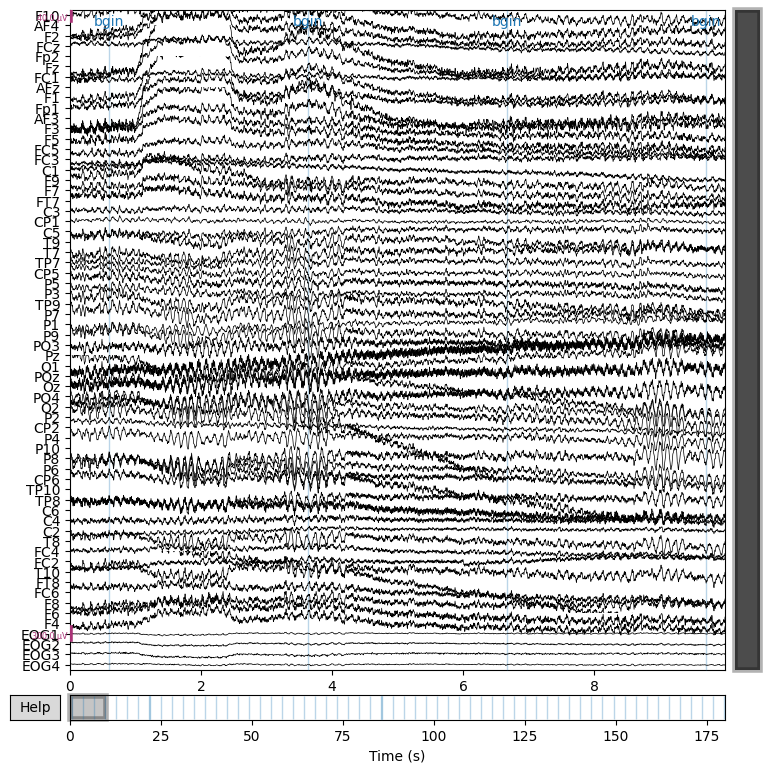

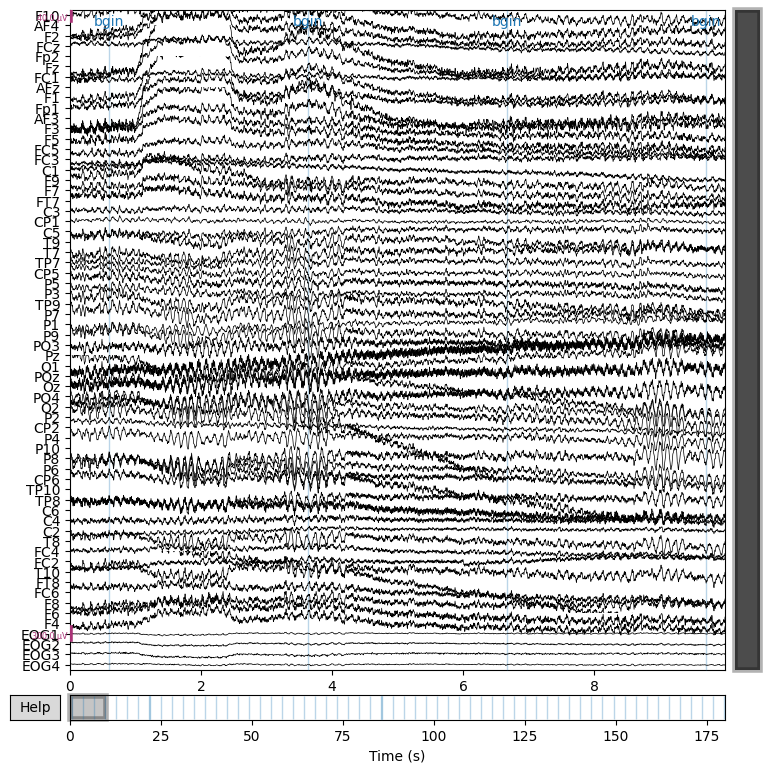

In [12]:
vref_drop.plot(
    n_channels = 64,
    bad_color = 'red',
    remove_dc = True
)

In [13]:
ref = vref_drop.copy()

ref.set_eeg_reference(ref_channels = 'average')

ref

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


<RawEEGLAB | sub-003_task-rest_eeg.set, 64 x 45001 (180.0 s), ~22.0 MiB, data loaded>

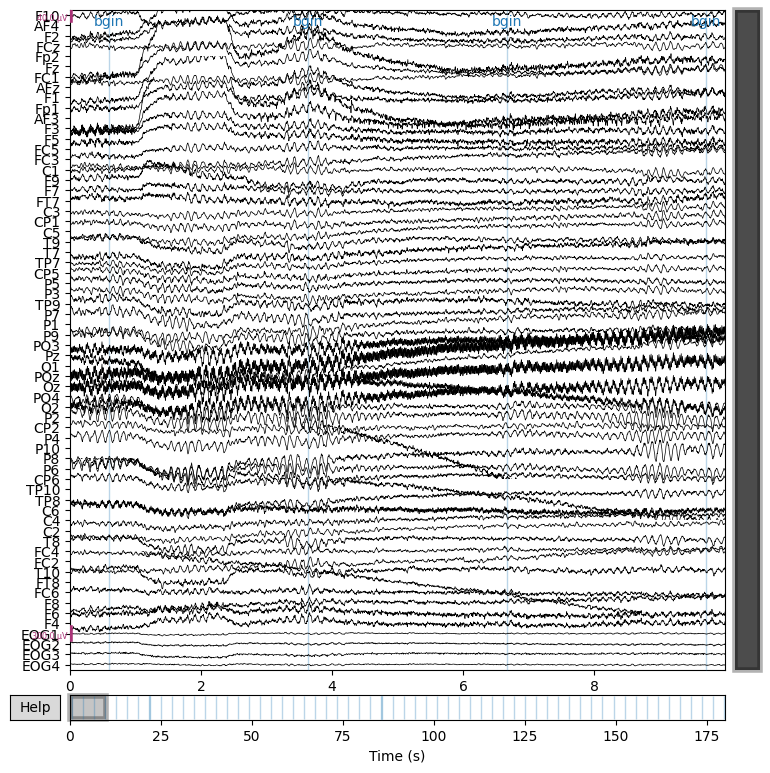

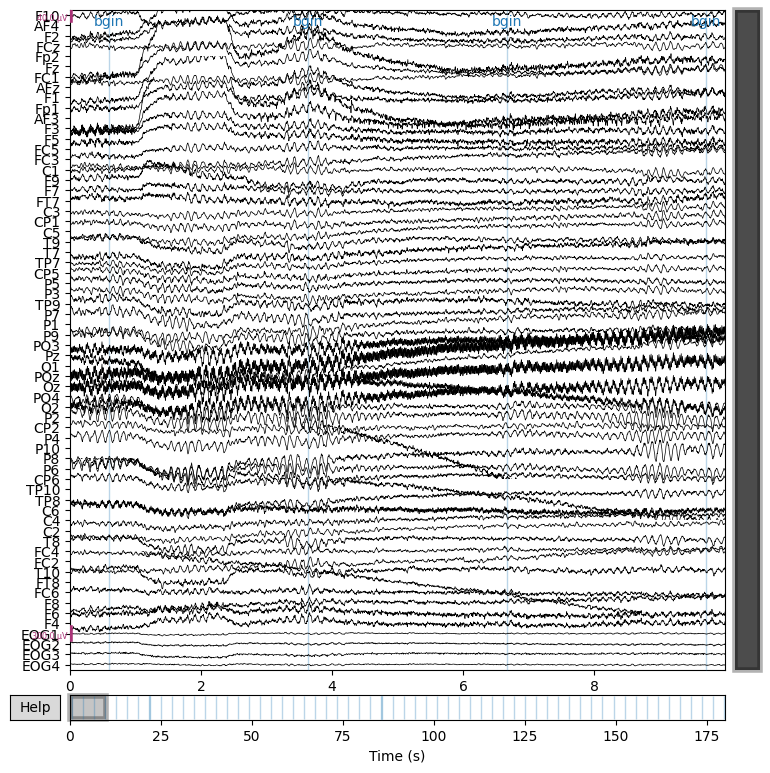

In [14]:
ref.plot(
    n_channels = 64,
    bad_color = 'red',
    remove_dc = True
)

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


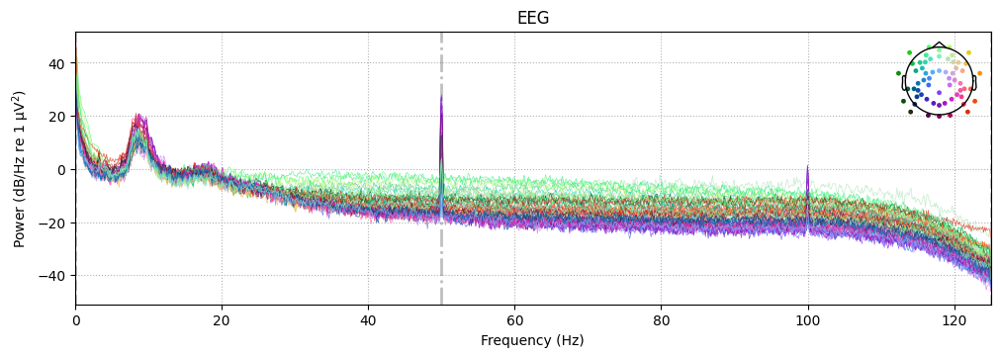

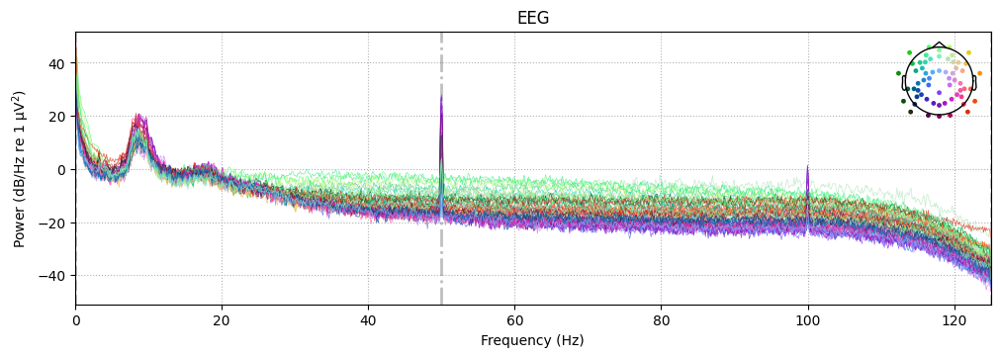

In [15]:
ref.compute_psd().plot()

In [16]:
notch = ref.copy()

notch.notch_filter(
    freqs=[50, 100],
    method='fir',
    verbose=True,
    fir_design = 'firwin'
)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower transition bandwidth: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz
- Filter length: 1651 samples (6.604 s)



<RawEEGLAB | sub-003_task-rest_eeg.set, 64 x 45001 (180.0 s), ~22.0 MiB, data loaded>

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


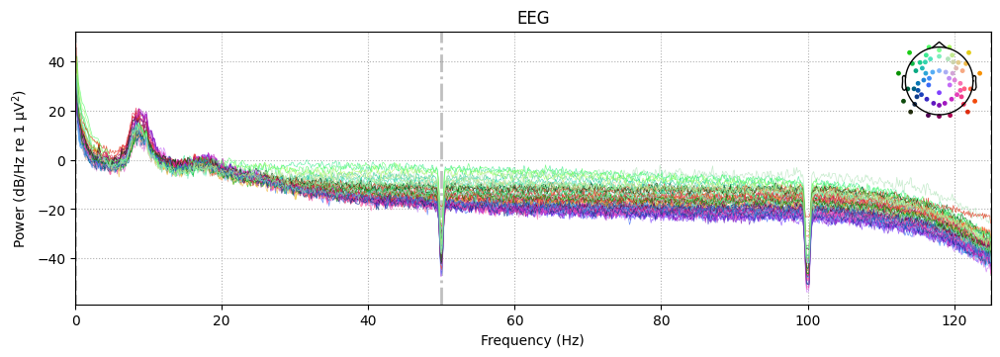

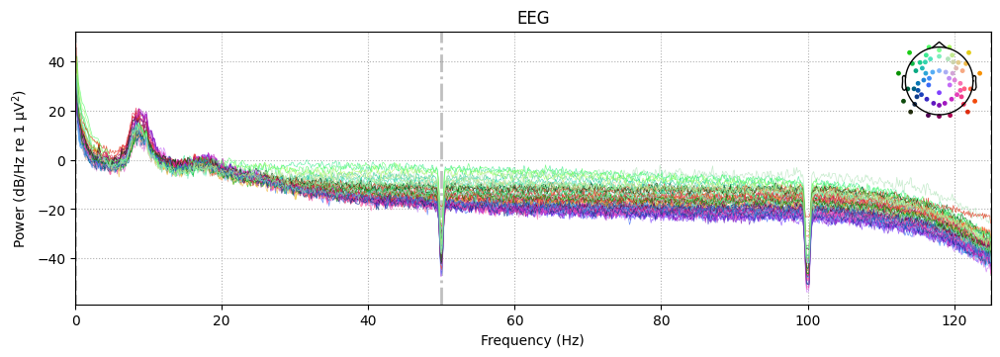

In [17]:
notch.compute_psd().plot()

In [18]:
bandpass = notch.copy()

bandpass.filter(
    l_freq = 0.5,
    h_freq = 40.0,
    method = 'fir',
    fir_design = 'firwin'
)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1651 samples (6.604 s)



<RawEEGLAB | sub-003_task-rest_eeg.set, 64 x 45001 (180.0 s), ~22.0 MiB, data loaded>

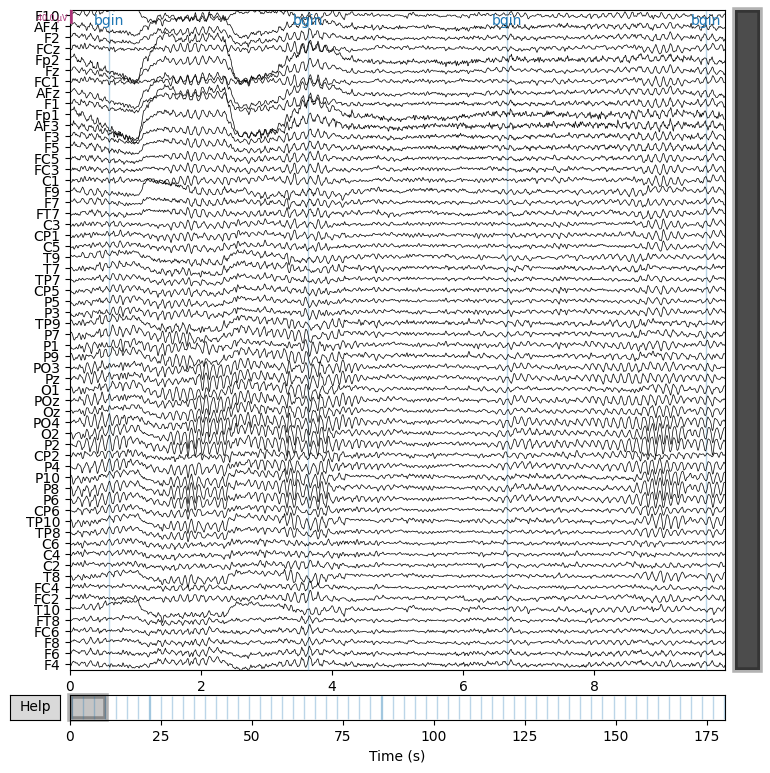

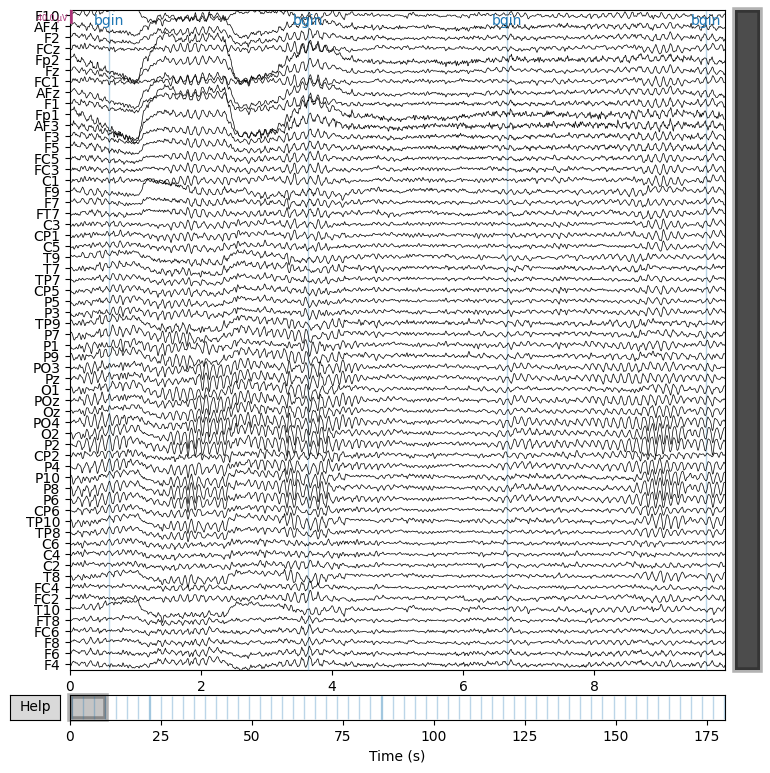

In [19]:
bandpass.plot(
    picks = 'eeg',
    n_channels = 65,
    bad_color = 'red',
    remove_dc = 'True'
)

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


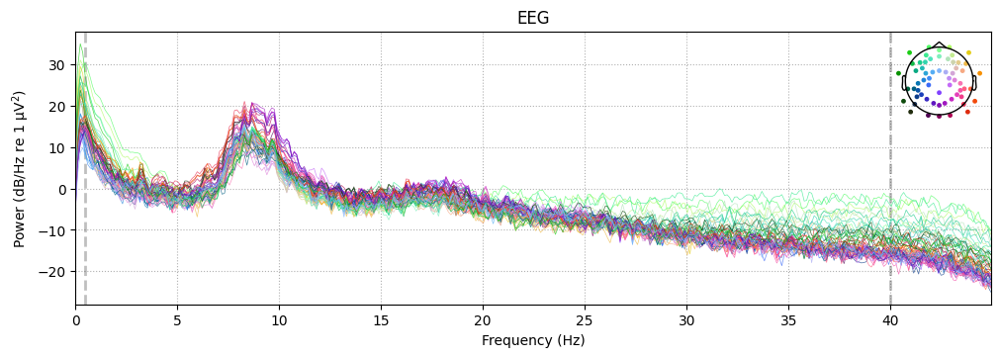

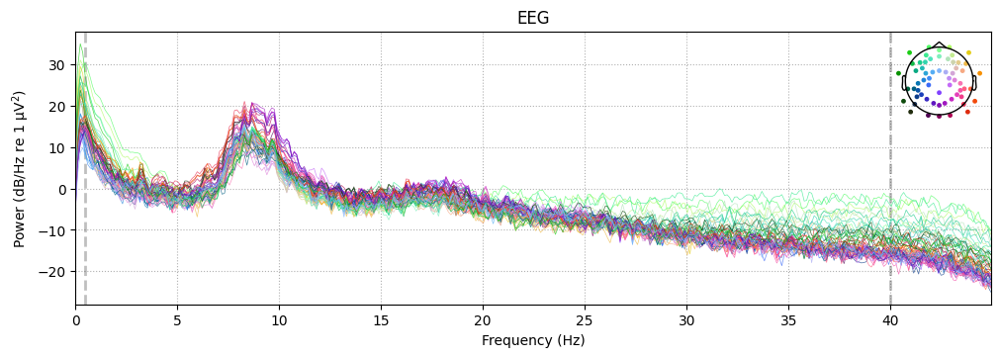

In [20]:
bandpass.compute_psd(fmin = 0, fmax = 45).plot()

# Step 3 **인공물 제거**

In [21]:
raw_ica = notch.copy().filter(l_freq = 1, h_freq = 100, method = 'fir', fir_design = 'firwin')

raw_ica.pick(['eeg', 'eog'])

ica = ICA(
    n_components = 0.999,
    method = 'infomax',
    fit_params = dict(extended = True),
    random_state = 42,
    max_iter = 'auto',
)

ica.fit(raw_ica, picks = 'eeg')

print(ica)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3.300 s)

Fitting ICA to data using 60 channels (please be patient, this may take a while)
Selecting by explained variance: 52 components
Computing Extended Infomax ICA
Fitting ICA took 19.4s.
<ICA | raw data decomposition, method: infomax (fit in 500 iterations on 45001 samples), 52 ICA components (60 PCA components available), channel types: eeg, no sources marked for exclusion>


In [22]:
# EOG 채널을 기준으로 눈깜빡임/안구운동 관련 성분 찾기
eog_inds, eog_scores = ica.find_bads_eog(raw_ica)

print("EOG-related ICA components:", eog_inds)
print("Scores:", eog_scores)

# 일단 후보 지정
ica.exclude = eog_inds

Using EOG channels: EOG1, EOG2, EOG3, EOG4
... filtering ICA sources
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 10.25 Hz)
- Filter length: 2500 samples (10.000 s)

... filtering target
Setting up band-pass filter from 1 - 10 Hz

FIR filter parameters
---------------------
Designing a two-pass forward and reverse, zero-phase, non-causal bandpass filter:
- Windowed frequency-domain design (firwin2) method
- Hann window
- Lower passband edge: 1.00
- Lower transition bandwidth: 0.50 Hz (-12 dB cutoff frequency: 0.75 Hz)
- Upper passband edge: 10.00 Hz
- Upper transition bandwidth: 0.50 Hz (-12 dB cutoff fre

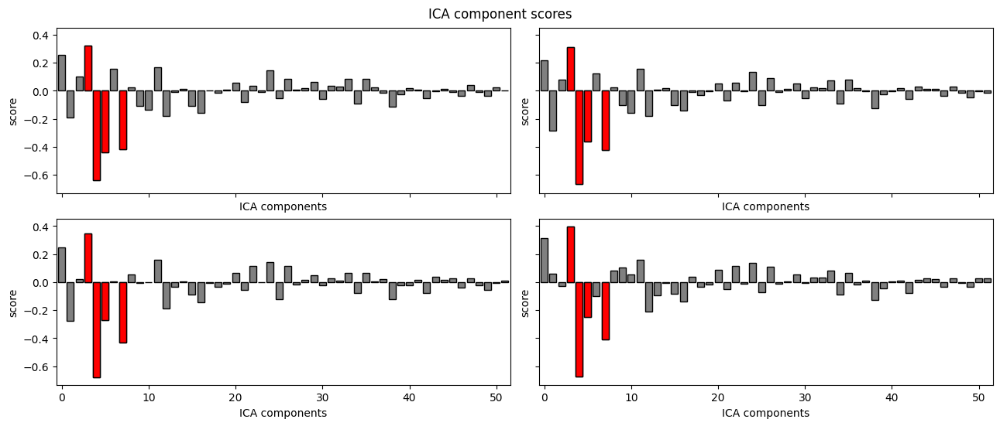

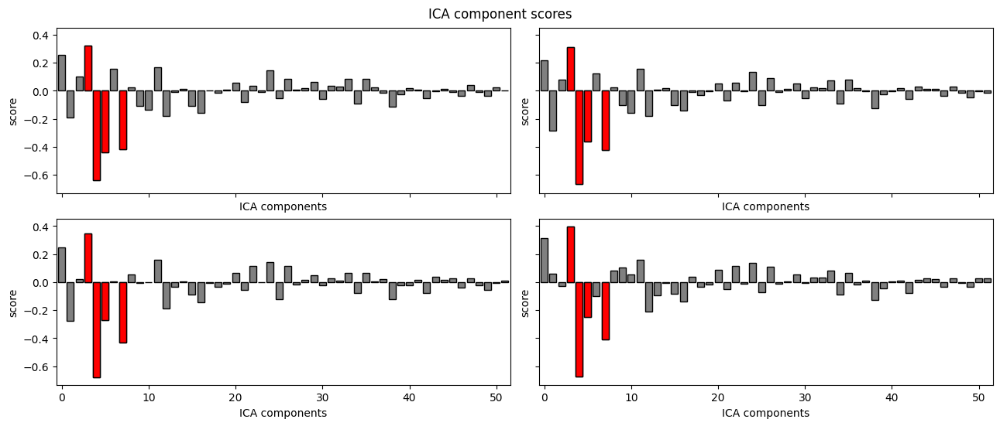

In [23]:
ica.plot_scores(eog_scores)

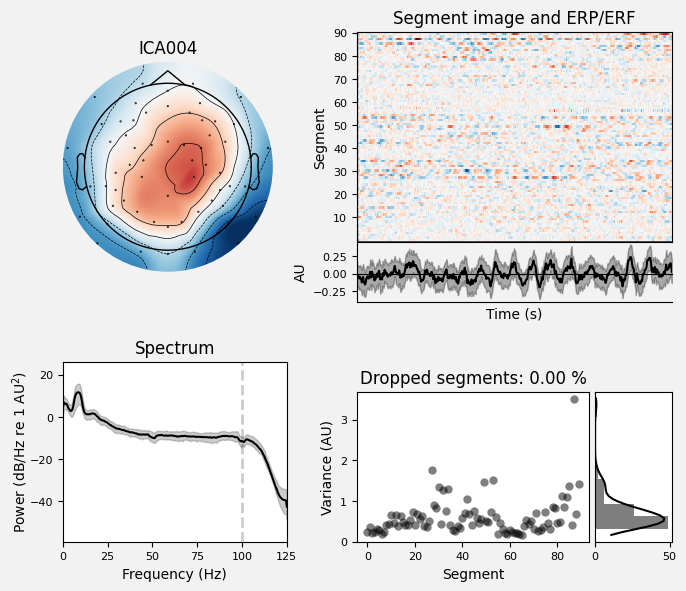

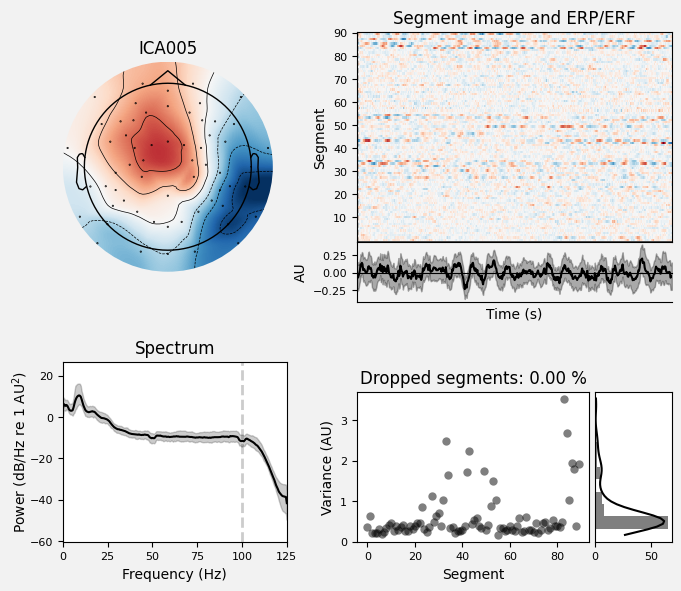

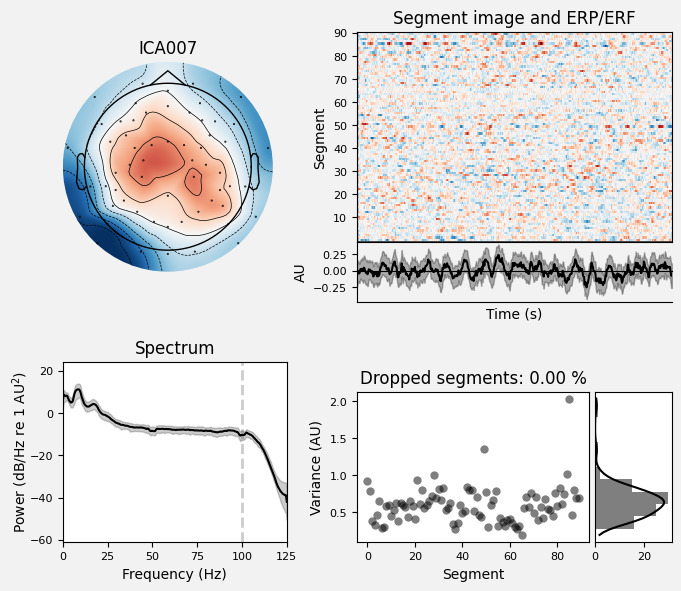

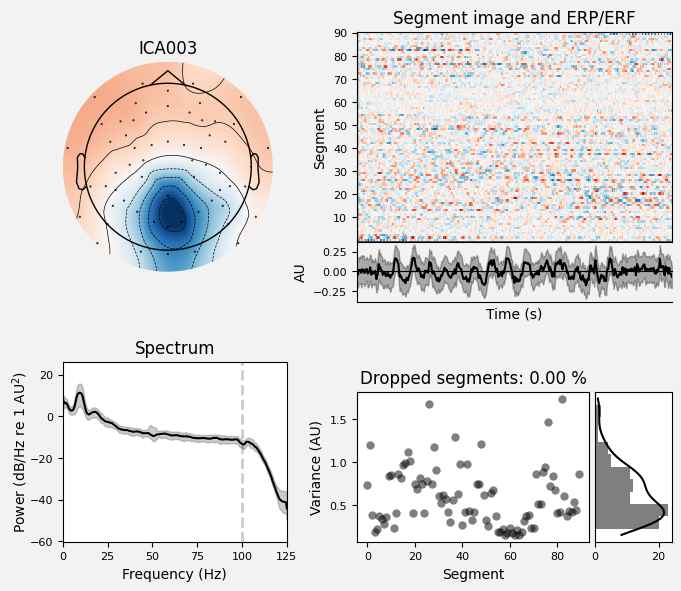

[<Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>,
 <Figure size 700x600 with 6 Axes>]

In [24]:
ica.plot_properties(raw_ica, picks=eog_inds, verbose = False)

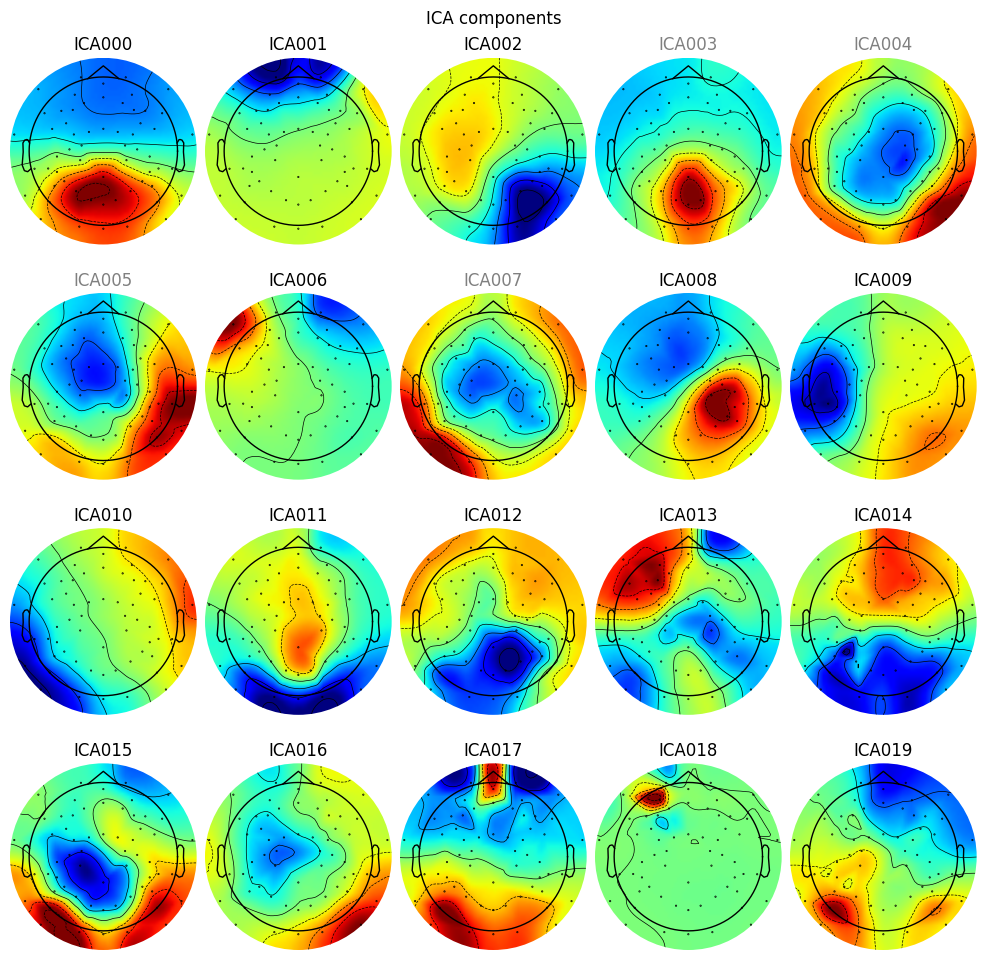

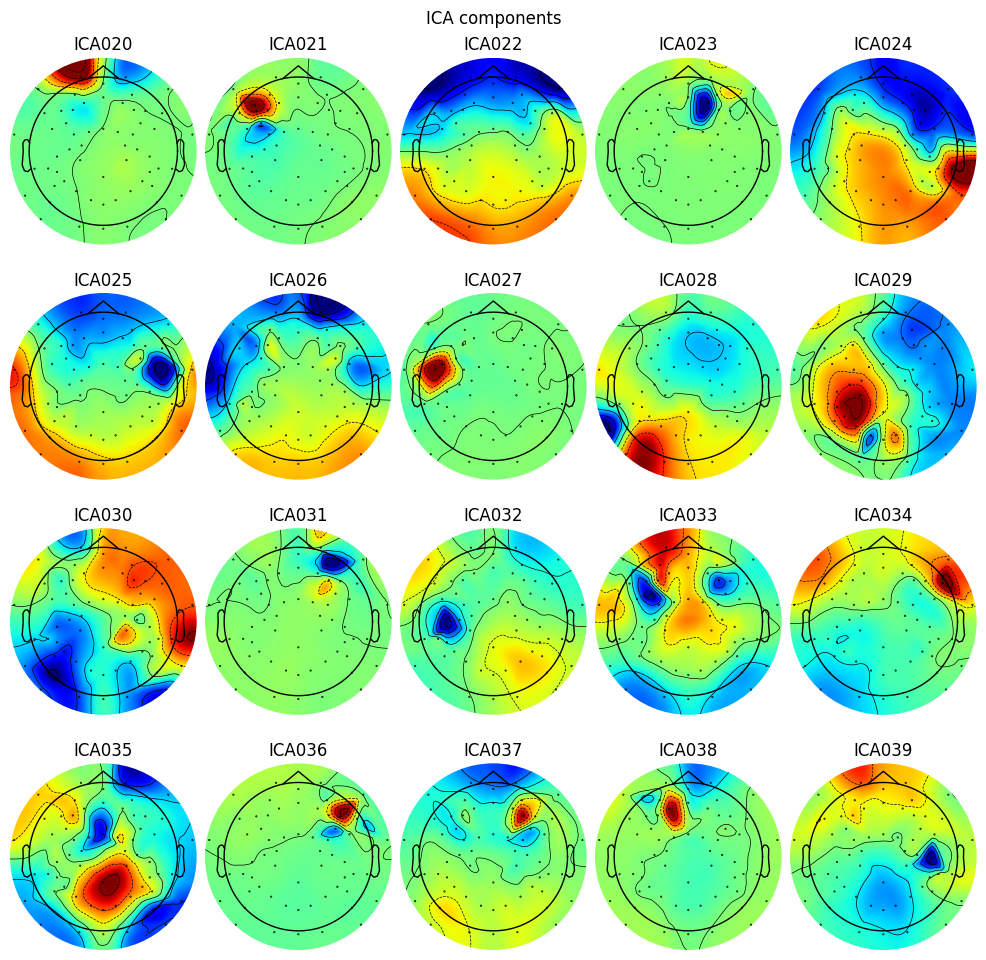

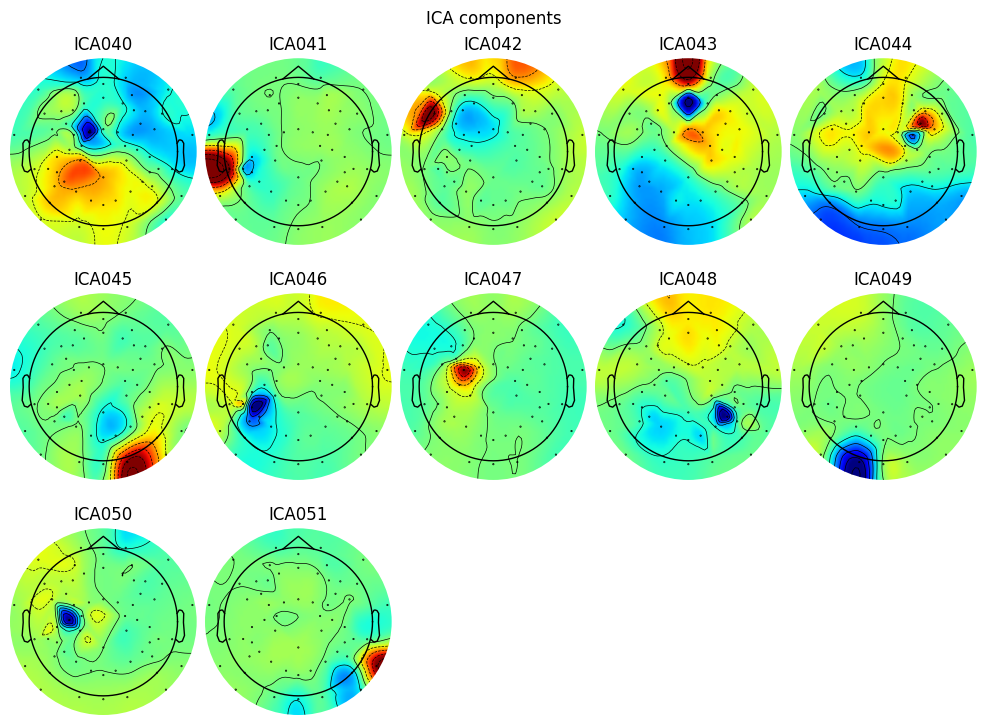

[<MNEFigure size 975x967 with 20 Axes>,
 <MNEFigure size 975x967 with 20 Axes>,
 <MNEFigure size 975x731.5 with 12 Axes>]

In [25]:
ica.plot_components(cmap = 'jet_r')

Creating RawArray with float64 data, n_channels=56, n_times=45001
    Range : 5000 ... 50000 =     20.000 ...   200.000 secs
Ready.


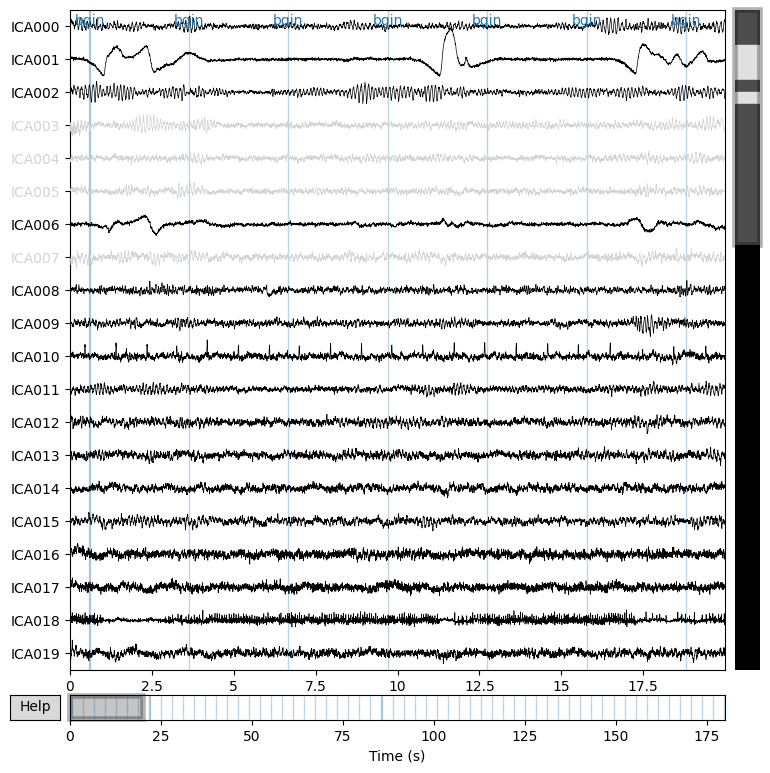

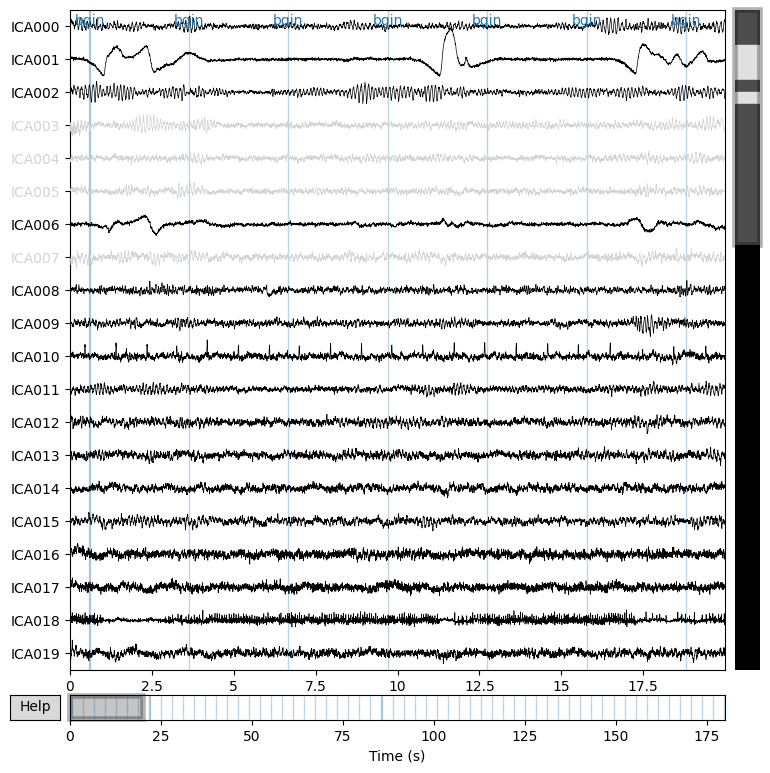

In [26]:
ica.plot_sources(inst = raw_ica)

In [27]:
clean = crop.copy()
ica.apply(clean)

Applying ICA to Raw instance
    Transforming to ICA space (52 components)
    Zeroing out 4 ICA components
    Projecting back using 60 PCA components


<RawEEGLAB | sub-003_task-rest_eeg.set, 65 x 45001 (180.0 s), ~22.4 MiB, data loaded>

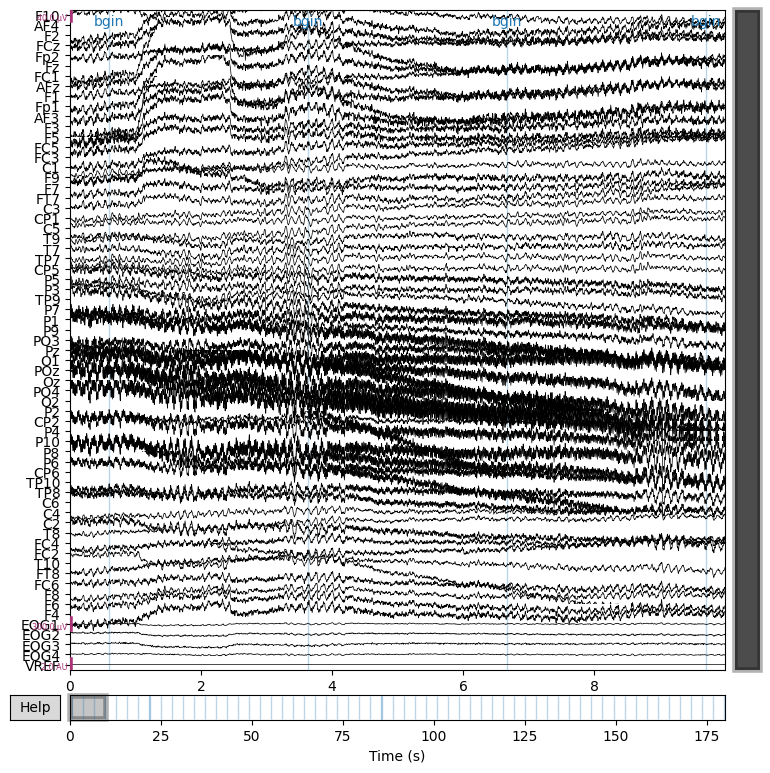

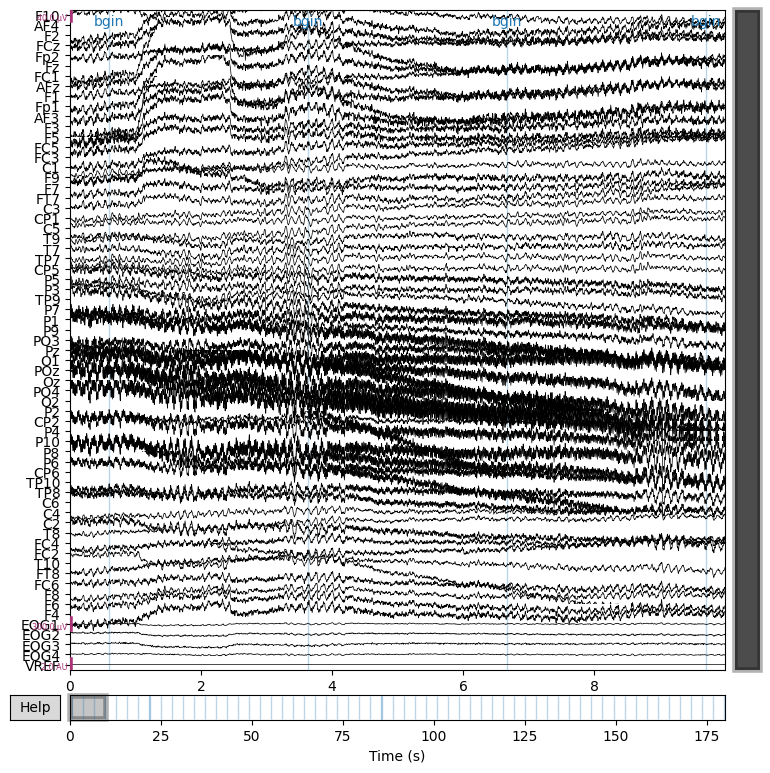

In [28]:
clean.plot(n_channels = 65,)

# 3-2 2nd ICA

In [29]:
raw_ica2 = notch.copy().filter(l_freq = 1, h_freq = 100, method = 'fir', fir_design = 'firwin')

ica = ICA(
    n_components = 0.999,
    method = 'infomax',
    fit_params = dict(extended = True),
    random_state = 42,
    max_iter = 'auto',
)

ica.fit(raw_ica2)

print(ica)

Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 1e+02 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 100.00 Hz
- Upper transition bandwidth: 25.00 Hz (-6 dB cutoff frequency: 112.50 Hz)
- Filter length: 825 samples (3.300 s)

Fitting ICA to data using 60 channels (please be patient, this may take a while)
Selecting by explained variance: 52 components
Computing Extended Infomax ICA
Fitting ICA took 18.1s.
<ICA | raw data decomposition, method: infomax (fit in 500 iterations on 45001 samples), 52 ICA components (60 PCA components available), channel types: eeg, no sources marked for exclusion>


In [30]:
# ICLabel 활용 자동 라벨링

ic_labels = label_components(raw_ica2, ica, method="iclabel")

print(ic_labels.keys())
print(ic_labels["labels"])

dict_keys(['y_pred_proba', 'labels'])
['brain', 'eye blink', 'brain', 'brain', 'brain', 'brain', 'eye blink', 'brain', 'brain', 'brain', 'heart beat', 'brain', 'brain', 'brain', 'brain', 'brain', 'brain', 'brain', 'muscle artifact', 'brain', 'muscle artifact', 'muscle artifact', 'eye blink', 'muscle artifact', 'brain', 'muscle artifact', 'other', 'other', 'muscle artifact', 'brain', 'brain', 'muscle artifact', 'brain', 'other', 'brain', 'brain', 'muscle artifact', 'other', 'muscle artifact', 'muscle artifact', 'brain', 'muscle artifact', 'muscle artifact', 'brain', 'brain', 'brain', 'other', 'brain', 'other', 'brain', 'channel noise', 'brain']


In [31]:
# ICLabel 결과를 보기 좋게 정리

pred_labels = ic_labels["labels"]
pred_proba = np.asarray(ic_labels["y_pred_proba"])

all_ic_info = []


if pred_proba.ndim == 2:
    classes = [
        "brain",
        "muscle artifact",
        "eye blink",
        "heart beat",
        "line noise",
        "channel noise",
        "other",
    ]
    class_to_idx = {c: j for j, c in enumerate(classes)}

    for comp_idx, lab in enumerate(pred_labels):
        row = {"component": comp_idx, "label": lab}
        for j, cls in enumerate(classes):
            row[cls] = float(pred_proba[comp_idx, j])
        all_ic_info.append(row)

else:
    for comp_idx, (lab, prob) in enumerate(zip(pred_labels, pred_proba)):
        all_ic_info.append({
            "component": comp_idx,
            "label": lab,
            "top_probability": float(prob),
        })

for row in all_ic_info:
    print(row)

{'component': 0, 'label': 'brain', 'top_probability': 0.9999924898147583}
{'component': 1, 'label': 'eye blink', 'top_probability': 0.981047511100769}
{'component': 2, 'label': 'brain', 'top_probability': 0.9998875856399536}
{'component': 3, 'label': 'brain', 'top_probability': 0.9999803900718689}
{'component': 4, 'label': 'brain', 'top_probability': 0.9999426603317261}
{'component': 5, 'label': 'brain', 'top_probability': 0.9997106790542603}
{'component': 6, 'label': 'eye blink', 'top_probability': 0.9497253894805908}
{'component': 7, 'label': 'brain', 'top_probability': 0.9997296333312988}
{'component': 8, 'label': 'brain', 'top_probability': 0.9998157024383545}
{'component': 9, 'label': 'brain', 'top_probability': 0.9928330183029175}
{'component': 10, 'label': 'heart beat', 'top_probability': 0.9722620844841003}
{'component': 11, 'label': 'brain', 'top_probability': 0.9549321532249451}
{'component': 12, 'label': 'brain', 'top_probability': 0.999456524848938}
{'component': 13, 'label

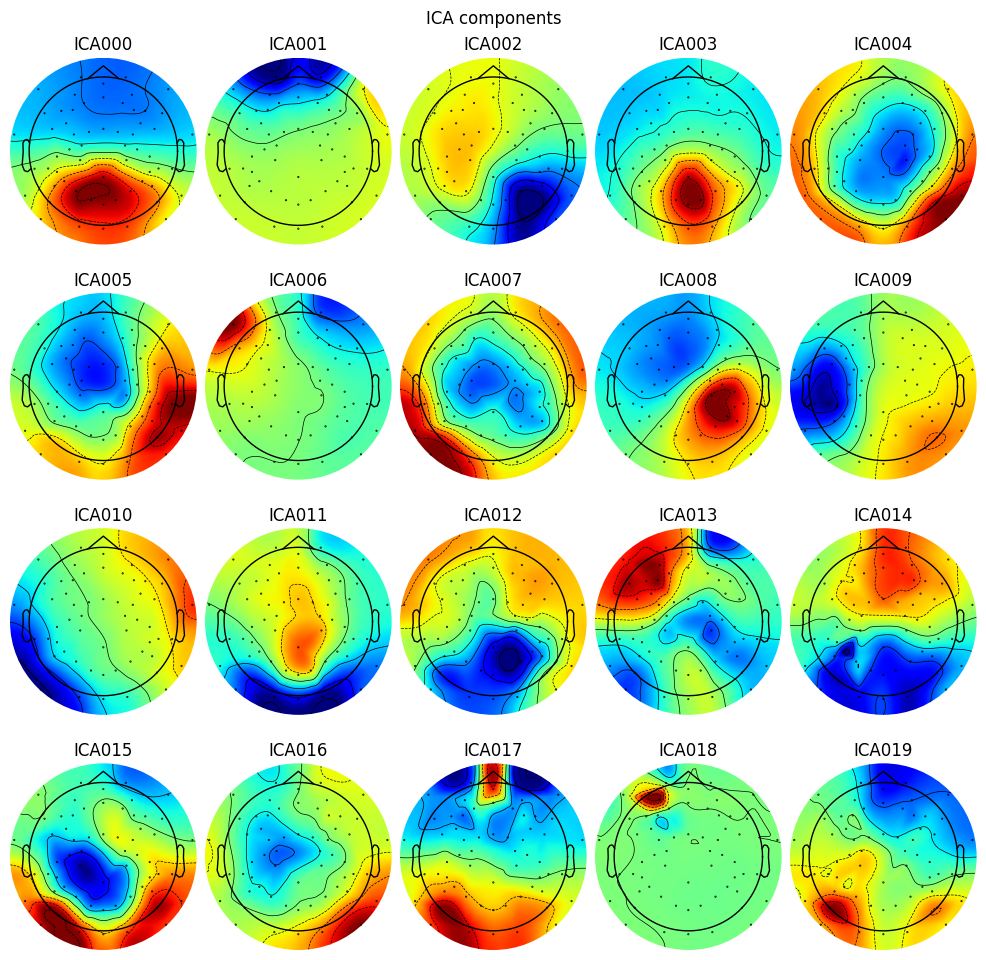

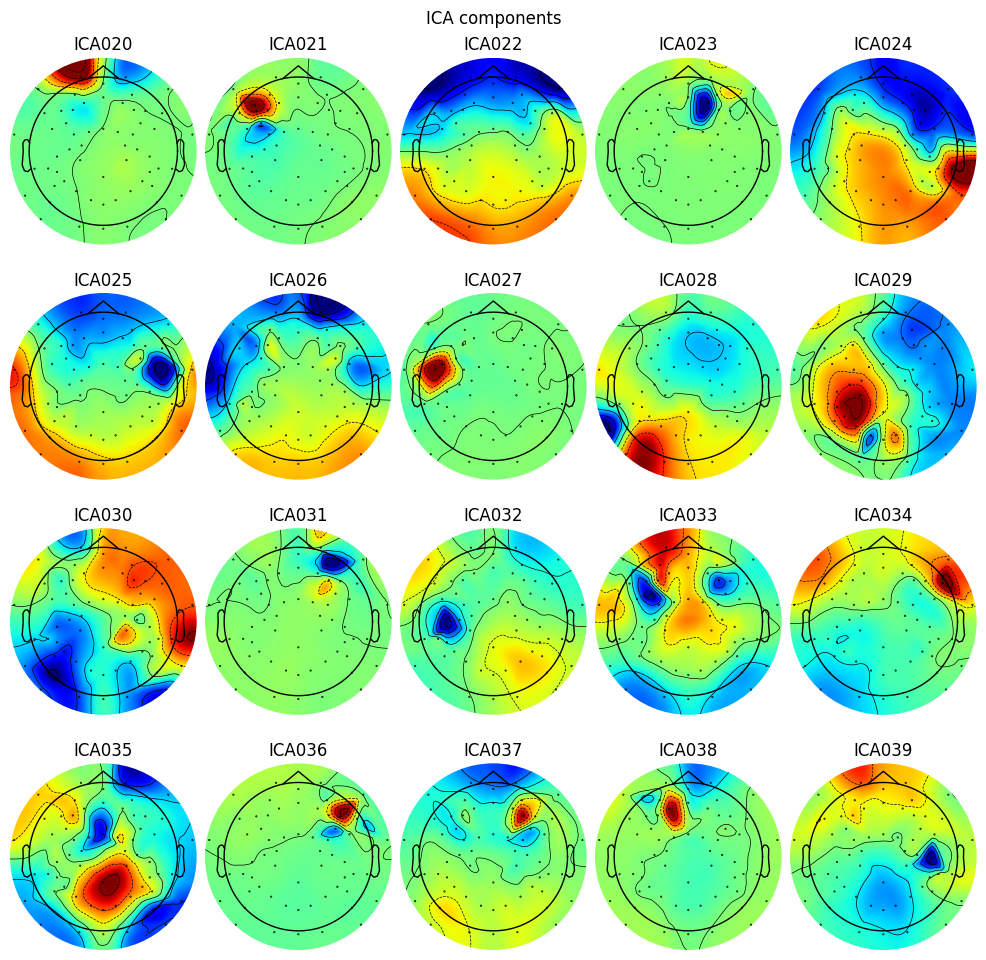

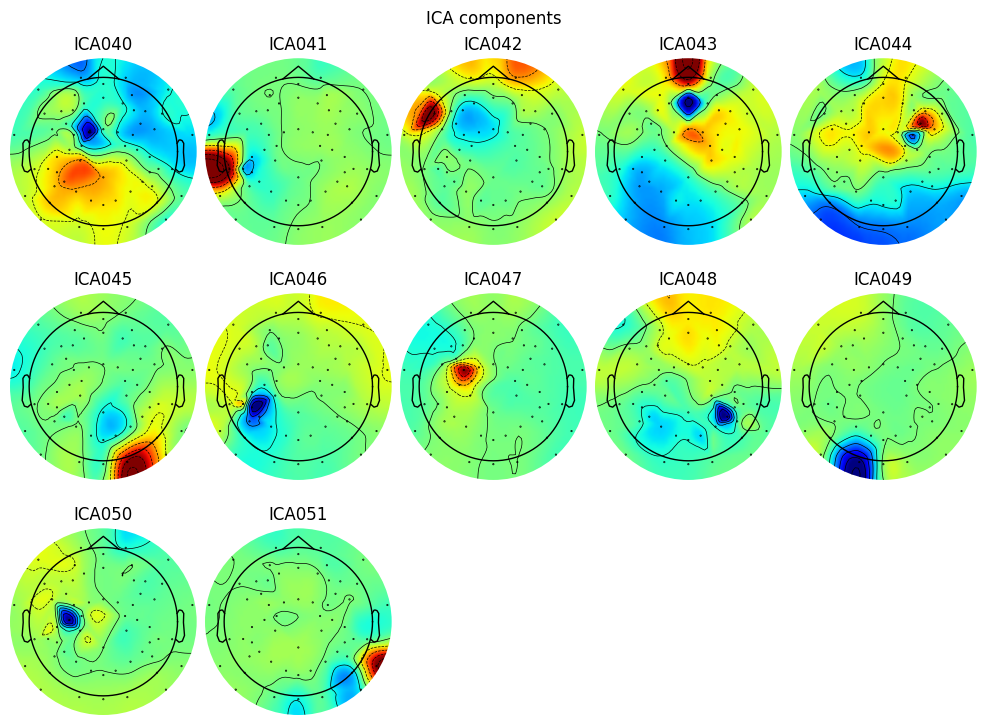

[<MNEFigure size 975x967 with 20 Axes>,
 <MNEFigure size 975x967 with 20 Axes>,
 <MNEFigure size 975x731.5 with 12 Axes>]

In [32]:
# 14. ICA compnent 확인

ica.plot_components(inst = raw_ica2, cmap = 'jet_r')

In [33]:
# 전체 properties 확인

ica.plot_properties(raw_ica2, picks=range(ica.n_components_), psd_args={"fmin": 0, "fmax": 40}, verbose = False)

Output hidden; open in https://colab.research.google.com to view.

Creating RawArray with float64 data, n_channels=56, n_times=45001
    Range : 5000 ... 50000 =     20.000 ...   200.000 secs
Ready.


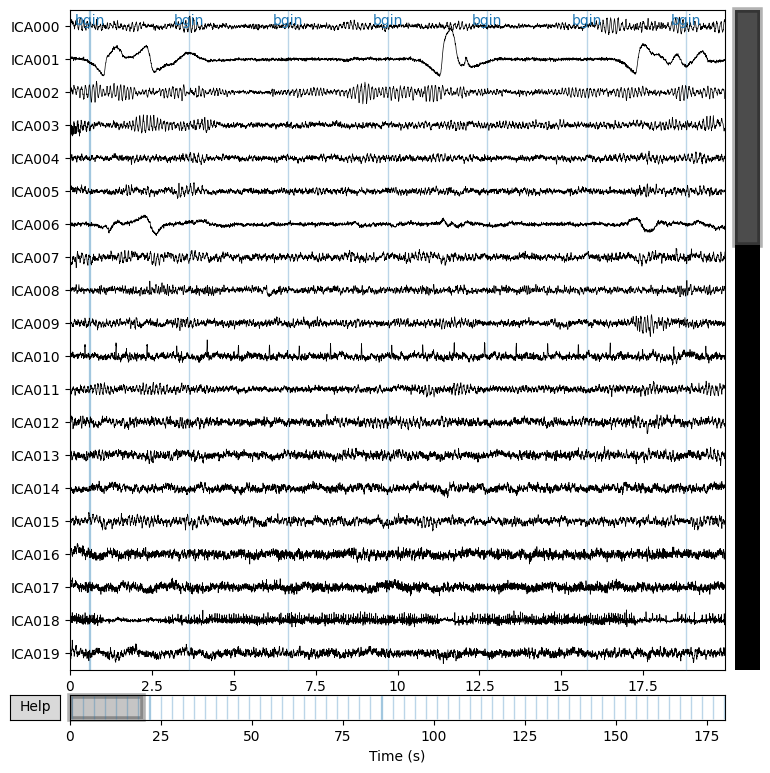

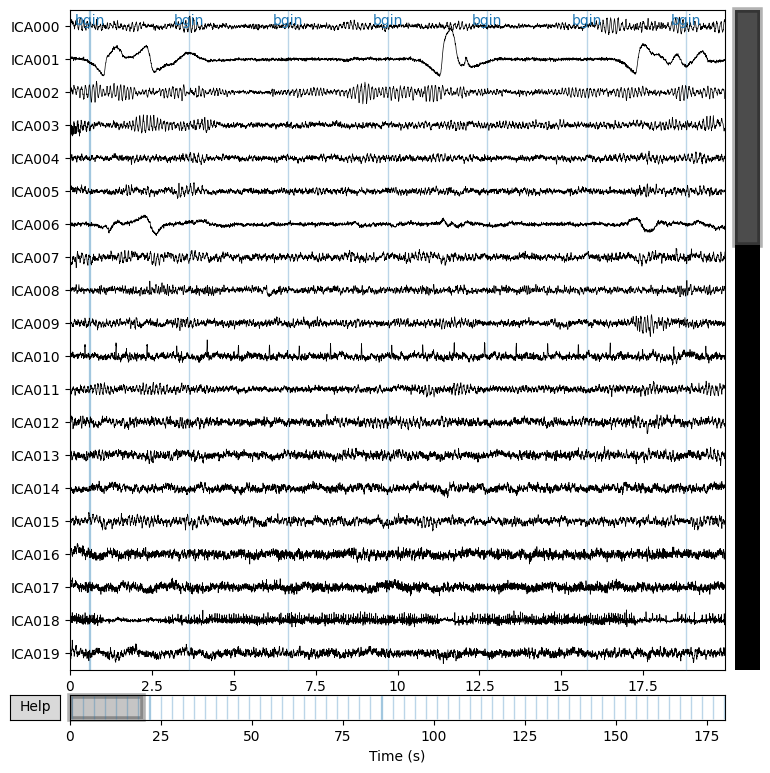

In [34]:
ica.plot_sources(inst = raw_ica2)

In [35]:
# ICLabel 자동 제거 기준
ICLABEL_EXCLUDE_LABELS = {
    "eye blink",
    "muscle artifact",
    "heart beat",
    "line noise",
    "channel noise",
}

ICLABEL_THRESH = {
    "eye blink": 0.70,
    "muscle artifact": 0.70,
    "heart beat": 0.70,
    "line noise": 0.70,
    "channel noise": 0.70,
}

In [36]:
# 13. ICLabel 기준 자동 exclude

exclude = []
exclude_detail = []

if pred_proba.ndim == 2:
    classes = [
        "brain",
        "muscle artifact",
        "eye blink",
        "heart beat",
        "line noise",
        "channel noise",
        "other",
    ]
    class_to_idx = {c: j for j, c in enumerate(classes)}

    for comp_idx, lab in enumerate(pred_labels):
        if lab in ICLABEL_EXCLUDE_LABELS:
            prob = float(pred_proba[comp_idx, class_to_idx[lab]])
            if prob >= ICLABEL_THRESH[lab]:
                exclude.append(comp_idx)
                exclude_detail.append(f"{comp_idx}:{lab}:{prob:.2f}")

else:
    for comp_idx, (lab, prob) in enumerate(zip(pred_labels, pred_proba)):
        prob = float(prob)
        if lab in ICLABEL_EXCLUDE_LABELS and prob >= ICLABEL_THRESH[lab]:
            exclude.append(comp_idx)
            exclude_detail.append(f"{comp_idx}:{lab}:{prob:.2f}")

ica.exclude = exclude

print("Excluded ICA components:", ica.exclude)
print("Exclude detail:", exclude_detail)

Excluded ICA components: [1, 6, 10, 18, 20, 21, 22, 23, 25, 28, 31, 36, 38, 41]
Exclude detail: ['1:eye blink:0.98', '6:eye blink:0.95', '10:heart beat:0.97', '18:muscle artifact:0.99', '20:muscle artifact:1.00', '21:muscle artifact:0.97', '22:eye blink:0.90', '23:muscle artifact:0.93', '25:muscle artifact:0.90', '28:muscle artifact:0.73', '31:muscle artifact:0.84', '36:muscle artifact:0.80', '38:muscle artifact:0.99', '41:muscle artifact:0.91']


In [37]:
post_ica = ica.apply(crop.copy())

post_ica

Applying ICA to Raw instance
    Transforming to ICA space (52 components)
    Zeroing out 14 ICA components
    Projecting back using 60 PCA components


<RawEEGLAB | sub-003_task-rest_eeg.set, 65 x 45001 (180.0 s), ~22.4 MiB, data loaded>

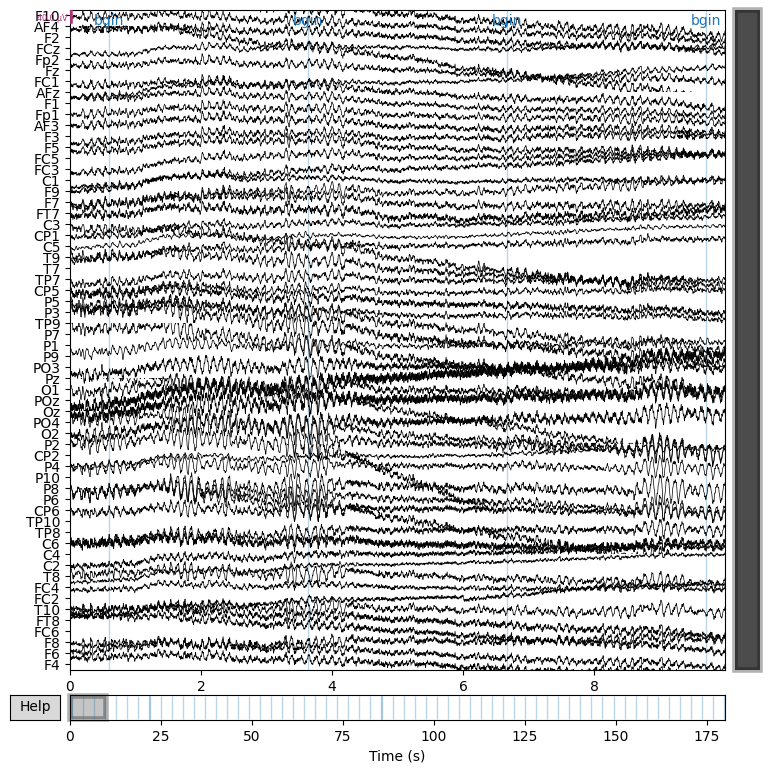

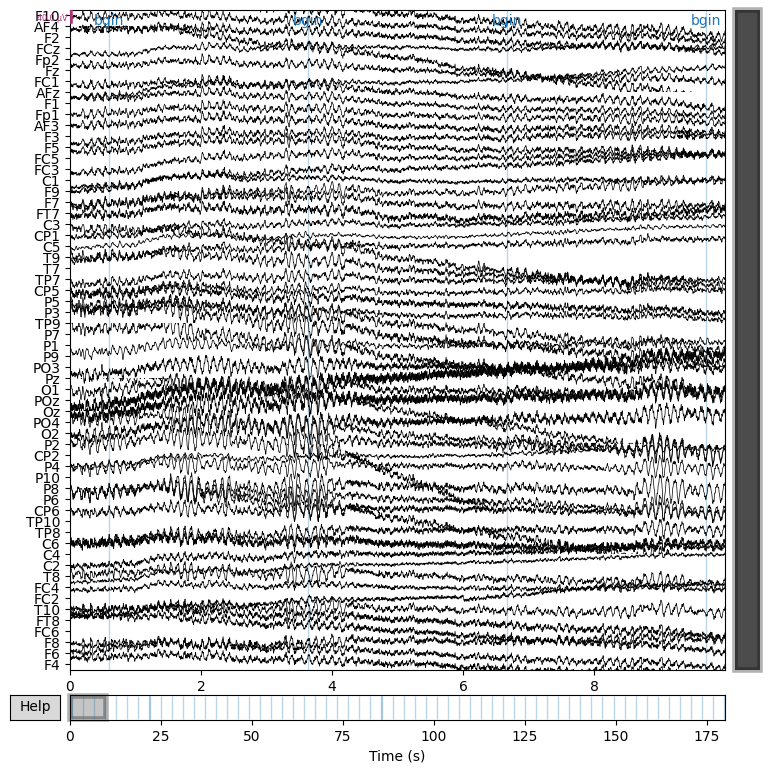

In [38]:
post_ica.plot(
    picks = 'eeg',
    n_channels = 64,
    bad_color='red'
)

Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


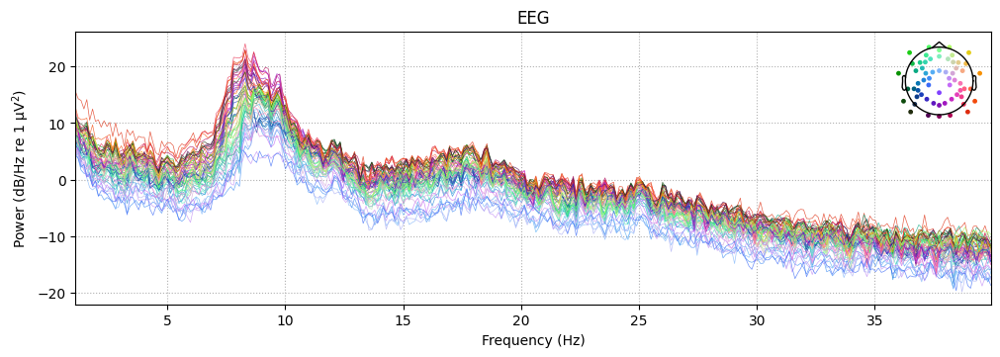

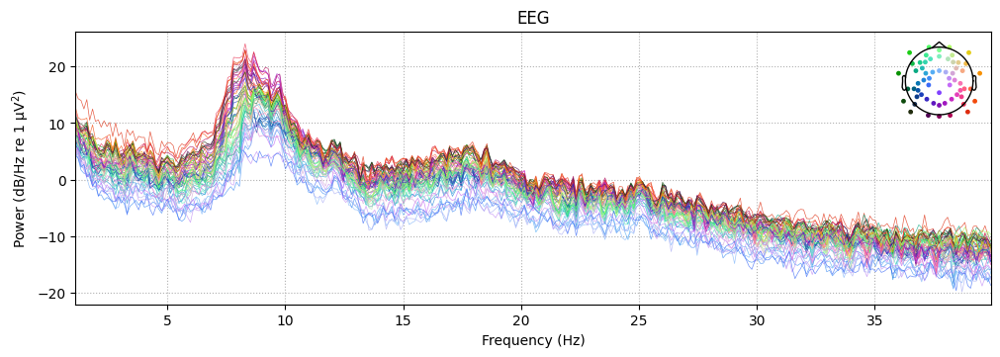

In [39]:
post_ica.compute_psd(fmin = 1, fmax = 40, method = 'welch').plot(average=False)

In [40]:
epochs = mne.make_fixed_length_epochs(post_ica, duration = 5, overlap = 0, preload = True )
epochs

Not setting metadata
36 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 36 events and 1250 original time points ...
0 bad epochs dropped


<Epochs | 36 events (all good), 0 – 4.996 s (baseline off), ~22.4 MiB, data loaded,
 '1': 36>

    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows
    Using multitaper spectrum estimation with 7 DPSS windows


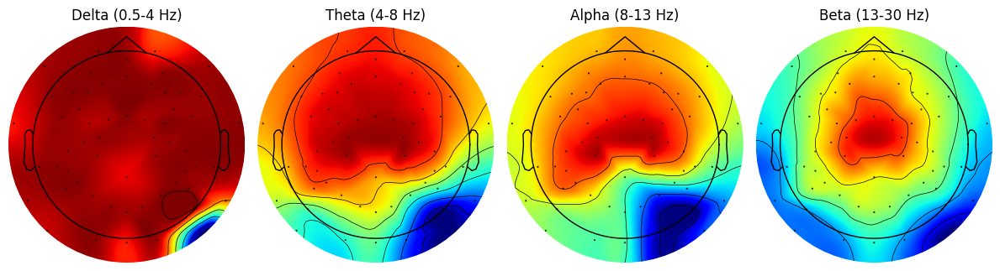

In [41]:
# EEG 채널만
epochs_eeg = epochs.copy().pick("eeg")


# 주파수 대역 정의
bands = {
    "Delta (0.5-4 Hz)": (0.5, 4),
    "Theta (4-8 Hz)": (4, 8),
    "Alpha (8-13 Hz)": (8, 13),
    "Beta (13-30 Hz)": (13, 30),
}

fig, axes = plt.subplots(1, len(bands), figsize=(12, 4))

for ax, (band_name, (fmin, fmax)) in zip(axes, bands.items()):
    # PSD 계산
    psd = epochs_eeg.compute_psd(
        method="multitaper",
        fmin=fmin,
        fmax=fmax,
        picks="eeg"
    )


    psd_data = psd.get_data()


    band_power = psd_data.mean(axis=0).mean(axis=1)  # (n_channels,)

    mne.viz.plot_topomap(
        band_power,
        epochs_eeg.info,
        cmap = 'jet_r',
        axes=ax,
        contours=6,
        show=False
    )
    ax.set_title(band_name)

plt.tight_layout()
plt.show()